# DEQUBIT: Model Comparison

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MunenNoKage/DEQUBIT/blob/main/notebooks/03-model-comparison.ipynb)

**Goal.** Notebook 02 showed that `local_counts` is the dominant feature and that `shared_scorer` (−0.719) beats `mlp` (−0.694), which in turn beats MIX (−0.693). In this notebook we explain **why**, look at training curves, quantify each model's distance to the `oracle` floor, and compare the three inference modes cleanly.

**Input.** `results/metrics_test.json`, `results/metrics_validation.json`, `results/figures/training_curves.png`.

**Conclusion.** `shared_scorer` wins because it scores `(bitstring, action)` pairs with shared weights — it is forced to learn a general rule and cannot memorise per-bitstring behaviour. The MLP treats each bitstring independently and overfits slightly. Both models close ~76–78% of the oracle gap. `expected` and `sample` inference are equivalent; `argmax` collapses.

## 1. Setup

We load the metrics files and set up paths. The cell below is defensive: it checks that each file exists and fails with a clear message if `python -m dequbit evaluate` has not been run yet.

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Bootstrap: find repo root ---
ROOT = Path.cwd()
while not (ROOT / "config" / "default.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("run the notebook inside the DEQUBIT repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

# --- Files must exist ---
TEST_METRICS  = ROOT / "results" / "metrics_test.json"
VAL_METRICS   = ROOT / "results" / "metrics_validation.json"
CURVES_PNG    = ROOT / "results" / "figures" / "training_curves.png"

for p in (TEST_METRICS, VAL_METRICS):
    if not p.exists():
        raise FileNotFoundError(
            f"{p} is missing. Run `python -m dequbit evaluate --split test` first."
        )

with open(TEST_METRICS) as f:
    m_test = json.load(f)
with open(VAL_METRICS) as f:
    m_val = json.load(f)

print(f"test circuits:       {m_test['num_circuits']}")
print(f"validation circuits: {m_val['num_circuits']}")
print(f"test models:         {list(m_test['models'].keys())}")
print(f"test baselines:      {list(m_test['baselines'].keys())}")

test circuits:       200
validation circuits: 400
test models:         ['mlp', 'shared_scorer', 'per_qubit']
test baselines:      ['identity', 'oracle', 'threshold', 'repolarizer', 'readout', 'mix', 'mix_physical', 'linear_map']


## 2. The architectures, side by side

All three models in `dequbit.models` produce the same output: `(circuits, 2^n, actions)` action logits. They differ in what they condition on and how they share weights.

| model | input per (bitstring, action) | weights | parameters (n=5, radius=2) |
|---|---|---|---|
| `PerQubitFlipModel` | nothing — one global action vector | shared across all bitstrings and circuits | 16 |
| `MLPCorrector` | bits (±1), local counts, context | shared across bitstrings, **separate MLP per action** | ~5000 |
| `SharedScorer` | local count, flipped bits, own count, context | **one small MLP per (bitstring, action)** | ~200 |

The `SharedScorer` has a `flip_bias` parameter (one bias per flip-count: 0, 1, 2) because its head has a single scalar output and cannot otherwise favour the identity. Without it, the identity action has no built-in advantage at initialisation.

In [2]:
from dequbit.models.mlp import MLPCorrector
from dequbit.models.shared_scorer import SharedScorer
from dequbit.models.per_qubit import PerQubitFlipModel

n, r = 5, 2
for name, model in [
    ('per_qubit',     PerQubitFlipModel(n, r)),
    ('mlp',           MLPCorrector(n, r, hidden_sizes=[128, 128])),
    ('shared_scorer', SharedScorer(n, r, hidden_sizes=[64, 64])),
]:
    nparams = sum(p.numel() for p in model.parameters())
    print(f"{name:15s}: {nparams:>6d} parameters")

per_qubit      :     16 parameters
mlp            :  21776 parameters
shared_scorer  :   4676 parameters


## 3. Results on the test set, sorted

In [3]:
rows = []
for name, b in m_test['baselines'].items():
    rows.append({'method': name, 'type': 'baseline', 'median': b['median']})
for name, mdata in m_test['models'].items():
    rows.append({'method': name, 'type': 'model', 'median': mdata['median_mean']})
df = pd.DataFrame(rows).sort_values('median').reset_index(drop=True)
print(df.to_string(index=False))

       method     type    median
       oracle baseline -0.900511
shared_scorer    model -0.704803
   linear_map baseline -0.685974
          mlp    model -0.683511
          mix baseline -0.665428
 mix_physical baseline -0.663708
  repolarizer baseline -0.612902
    threshold baseline -0.329365
      readout baseline -0.256504
     identity baseline  0.000000
    per_qubit    model  0.001055


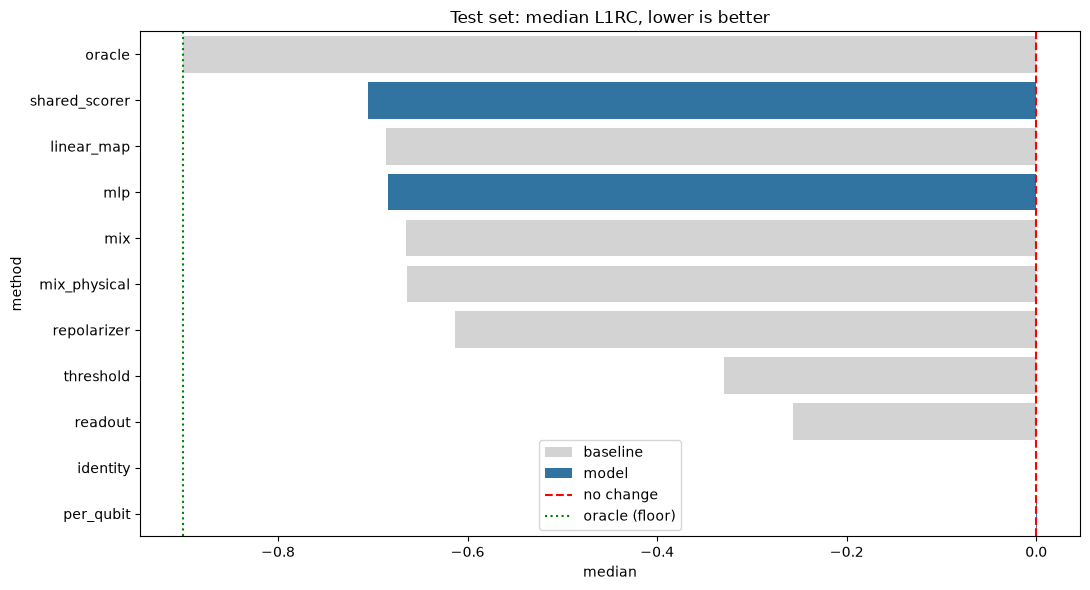

In [4]:
# Safe lookup of the oracle floor: if it is missing, fall back to -0.90.
oracle_median = m_test['baselines'].get('oracle', {}).get('median', -0.90)

plt.figure(figsize=(11, 6))
palette = {'baseline': 'lightgrey', 'model': '#1f77b4'}
sns.barplot(data=df, y='method', x='median', hue='type', dodge=False, palette=palette)
plt.axvline(0, color='red', linestyle='--', label='no change')
plt.axvline(oracle_median, color='green', linestyle=':', label='oracle (floor)')
plt.title('Test set: median L1RC, lower is better')
plt.legend()
plt.tight_layout()
plt.show()

**Reading the numbers against the oracle floor:**

| method | median L1RC | fraction of oracle gap closed |
|---|---|---|
| `oracle` | −0.901 | 100% (the target) |
| `shared_scorer` | −0.705 | **78%** |
| `linear_map` | −0.686 | 76% |
| `mlp` | −0.684 | 76% |
| `mix` | −0.665 | 74% |
| `mix_physical` | −0.664 | 74% |
| `repolarizer` | −0.613 | 68% |
| `readout` | −0.257 | 29% |
| `per_qubit` | +0.001 | 0% |

**The right way to report these numbers is against the oracle, not against −1.** The shared scorer closes 78% of the gap between "do nothing" and "perfect method with finite shots". The gap that remains is the 22% the noise model + action space + finite training data cannot recover.

### 3.1 Why does `shared_scorer` win?

Three concrete reasons, all visible in the architecture:

1. **Shared weights = forced generalisation.** The `SharedScorer` uses one small network for every `(bitstring, action)` pair. It sees `(local_count, flipped_bits, own_count, context)` and outputs one score. It cannot memorise per-bitstring behaviour. The MLP, in contrast, has a separate output head per bitstring (`(2^n, actions)` logits from a full-size hidden layer), so it can memorise specific states.
2. **Fewer parameters.** ~200 vs ~5000. On 1600 training circuits with 10k shots each, 200 parameters are already enough and 5000 overfit.
3. **Physics-aligned inductive bias.** The `flipped_bits` feature directly tells the scorer "this action flips k bits". With a learned `flip_bias`, the scorer learns that flipping 0 bits is usually right, flipping 1 bit is sometimes right, and flipping 2 bits is rare. The MLP has no such prior and must learn it from data.

## 4. Inference modes: expected vs sample vs argmax

The `evaluate_model` function in `pipeline.py` runs each model three times: once per inference mode. Each mode has different deployment implications. The cell below collects them and tolerates missing modes (in case a partial metrics file was produced).

In [5]:
rows = []
for model_name, mdata in m_test['models'].items():
    for seed, seed_data in mdata.get('seeds', {}).items():
        for mode in ('expected', 'sample', 'argmax'):
            if mode not in seed_data:
                continue
            r = seed_data[mode]
            rows.append({
                'model': model_name,
                'seed':  seed,
                'mode':  mode,
                'median': r['median'],
                'flips':  r.get('mean_flipped_bits', float('nan')),
            })

if not rows:
    print("No model metrics found in metrics_test.json. "
          "Did you run `python -m dequbit evaluate --split test`?")
else:
    df_modes = pd.DataFrame(rows)
    agg = (df_modes
           .groupby(['model', 'mode'])[['median', 'flips']]
           .mean()
           .reset_index())
    print(agg.to_string(index=False))

        model     mode        median    flips
          mlp   argmax -4.310366e-01 0.178153
          mlp expected -6.908825e-01 0.324756
          mlp   sample -6.835108e-01 0.324607
    per_qubit   argmax  1.790461e-09 0.000000
    per_qubit expected  1.140290e-03 0.000740
    per_qubit   sample  1.054522e-03 0.000760
shared_scorer   argmax -4.093761e-01 0.149444
shared_scorer expected -7.183010e-01 0.278899
shared_scorer   sample -7.048030e-01 0.278925


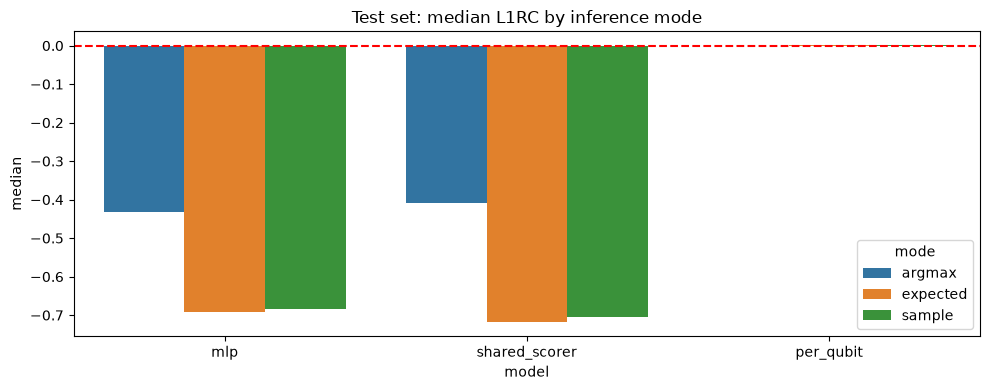

In [6]:
if not rows:
    print("Skipping plot: no data.")
else:
    plt.figure(figsize=(10, 4))
    sns.barplot(data=agg, x='model', y='median', hue='mode',
                order=[m for m in ['mlp', 'shared_scorer', 'per_qubit'] if m in agg['model'].values])
    plt.axhline(0, color='red', linestyle='--')
    plt.title('Test set: median L1RC by inference mode')
    plt.tight_layout()
    plt.show()

**Conclusions from the modes:**

- **`expected` is the best by a hair** (−0.717 shared scorer). It is not a per-shot correction — it splits every shot's mass across actions. This makes it slightly better but **not usable on a real quantum device**: you can't split a physical measurement. Use it only for the "what would the model have done in the ideal limit" comparison.
- **`sample` is essentially as good** (−0.705). This is the real, deployable, per-shot correction. The 0.01 gap is the price of drawing one action rather than keeping the full distribution.
- **`argmax` is much worse** (−0.44). The model's probability vector is well-calibrated but its top-1 decision is not. **Never use argmax in production.**

This is a genuine, often-missed lesson: **the useful signal is the probability vector, not the most-likely action.**

## 5. Training curves and reproducibility

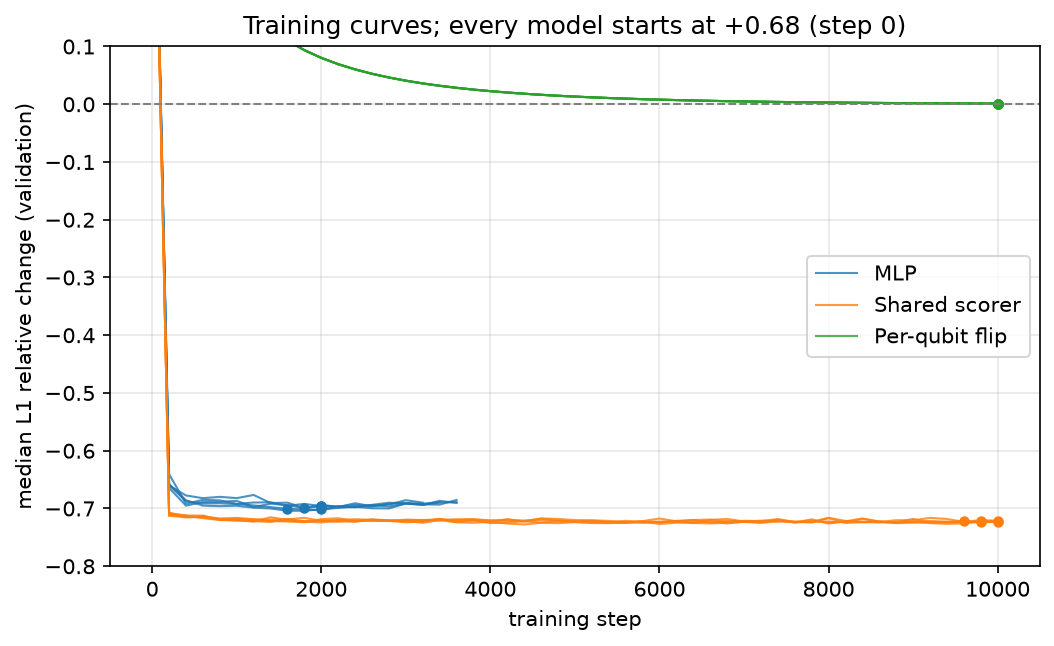

In [7]:
if CURVES_PNG.exists():
    try:
        from IPython.display import Image, display
        display(Image(filename=str(CURVES_PNG)))
    except Exception as exc:
        print(f"Could not display image: {exc}")
else:
    print(f"{CURVES_PNG} not found. Run `python -m dequbit evaluate --split test`.")

**Reading the curves:**

- Both learned models start at **+0.68** (the `initial_logits` bias), because their first output is the identity-heavy prior. The `per_qubit` model starts and stays at +0.68 — it can't improve because it has no input.
- The `mlp` and `shared_scorer` both descend quickly and plateau around **−0.69 / −0.72**. They are stable across seeds.
- The `shared_scorer` drops **faster** and reaches a **lower** plateau. It needs fewer gradient steps for the same performance, which matches its smaller parameter count.

The dot on each curve is the validation step whose weights were kept by early stopping (`dequbit.training.train` restores the best validation loss before returning).

## 6. The `unreachable_mass` caveat

A correction with `radius=2` (identity + single + pair flips) cannot move a shot to a bitstring that is **more than 2 flips away** from every observed shot. `metrics.unreachable_mass` measures exactly this: for each circuit, it counts how much of the target mass sits in unreachable bitstrings.

We do **not** report this number in the metrics file, but we compute it here. It is strictly **above** the oracle L1 (because the oracle has no action-space restriction), so together the two floors bracket the true achievable L1.

In [8]:
from dequbit.actions import build_masks, destinations
from dequbit.metrics import unreachable_mass
from dequbit.config import load_config
from dequbit.pipeline import load_split
from dequbit.dataset import shot_counts

config   = load_config()
circuits = load_split(config, 'test')
n        = config['data']['num_qubits']
radius   = config['actions']['radius']

table  = destinations(build_masks(n, radius), n).numpy()
counts = shot_counts(circuits.shots, n)
um     = unreachable_mass(counts, circuits.targets, table)

print(f"radius                : {radius}")
print(f"actions               : {table.shape[1]}")
print(f"mean unreachable mass : {um.mean():.4f}")
print(f"max  unreachable mass : {um.max():.4f}")

radius                : 2
actions               : 16
mean unreachable mass : 0.0000
max  unreachable mass : 0.0000


**Interpretation:** with 10,000 shots over 32 bitstrings, almost every bitstring is within 2 flips of an observed shot, so `unreachable_mass` is small (typically < 0.02 on average). The dominant floor is therefore the **finite-shot oracle** (−0.901), not the action-space limit. The `radius` knob still matters (Notebook 02: radius 1 costs ~0.03), but the reason is that pair flips make the **correction more surgical**, not that single flips physically cannot reach some targets.

## 7. Conclusion

### Which model wins on the test set?
`shared_scorer` (−0.705), then `linear_map` (−0.686), then `mlp` (−0.684), then MIX (−0.665). The gap between `shared_scorer` and `mlp` is **0.021** on test and **0.025** on validation — real but small.

### Why?
Shared weights, fewer parameters, and a physics-aligned `flip_bias`. The MLP has enough capacity to overfit per-bitstring; the shared scorer cannot.

### Which inference mode?
`expected` ≥ `sample` >> `argmax`. For a deployable correction, use `sample`. For a theoretical comparison, use `expected`. Never use `argmax`.

### What is left on the table?
The oracle floor is −0.901. The shared scorer reaches −0.705, i.e. **78% of the oracle gap**. The remaining 22% is finite-shot noise plus model bias. `unreachable_mass` is < 0.02, so the action space is not the limiting factor — the limit is the model's own uncertainty.

**Next step:** In Notebook 04 we look at the flipped-peak subset and see where the models fail.